# Domain shift analysis — CLIP neighborhoods, coverage and clustering

Compare real and synthetic images from six datasets in the **L2-normalized CLIP ViT-B/32 embedding space** (`openai/clip-vit-base-patch32`). The goal is to explore whether local domain overlap, synthetic-to-real proximity and coverage show patterns consistent with downstream data-augmentation results. **No classifier is trained.**

We keep the original workflow: balanced random sampling, CLIP embeddings, real-only k-means with a dataset-specific elbow, and the joint t-SNE **Domain View** and **Cluster View**. The Domain View shows **only real and synthetic points**, without boundaries or accuracy values.

**Primary exploratory measures** (computed in the original 512-D CLIP space):

1. **Cross-domain k-NN mixing** — proportion of nearest neighbors that belong to the opposite domain (0 = segregated; about 0.5 = locally mixed in a balanced sample).
2. **Density** — number of real-data k-NN balls containing each synthetic sample, divided by k. Can exceed 1.
3. **Coverage** — fraction of real samples whose real-data k-NN neighborhood contains at least one synthetic sample (0–1).

**Additional interpretable diagnostics:** sample-based precision and recall (k-NN manifold method); median cross-domain / same-domain nearest-neighbor distance ratios (real→synthetic and synthetic→real); occupancy overlap across real-trained clusters; synthetic distance to its assigned real centroid relative to the real cluster's 95th-percentile radius; and t-SNE local-neighborhood preservation.

The *density* and *coverage* definitions follow [Naeem et al., ICML 2020](https://proceedings.mlr.press/v119/naeem20a.html), and sample-based manifold *precision/recall* follow [Kynkäänniemi et al., NeurIPS 2019](https://research.nvidia.com/publication/2019-12_improved-precision-and-recall-metric-assessing-generative-models). The other diagnostics are defined explicitly in the notebook rather than presented as standard published metrics. **All numerical domain measures use 512-D CLIP distances, never t-SNE distances.**

> This is an **exploratory analysis, not a proof** that distribution proximity causes augmentation gains. CLIP image-level features can be dominated by background, perspective or class composition, and several measures depend on sample size and k.

**Dependencies:** `numpy`, `pandas`, `pillow`, `matplotlib`, `scikit-learn`, `torch`, `transformers`. Set dataset paths below; outputs are saved in `figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import pairwise_distances
import pandas as pd
from transformers import CLIPModel, CLIPProcessor

# ============================================================
# 1. CONFIGURATION (paths retained from the original notebook)
# ============================================================
'''DATASETS = {
    "Vessels & Boats": ("datasets_sdb/fernando_ultralytics/images/train", "datasets/sFERNANDO_FLUX29B/images"),
    "KITTI": ("datasets/kitti/images/train", "datasets_sda/sKITTI_FLUXFP8/images"),
    "African Wildlife": ("datasets/african-wildlife/images/train", "datasets/sAFRICANWILDLIFE_FLUXFP8/images"),
    "PASCAL VOC 2012": ("datasets/VOC/images/train", "datasets/sVOC_FLUXFP8/images"),
    "Home Objects": (
        "/home/josericardopenase/Escritorio/datasets/homeobjects-3K/images/train",
        "/home/josericardopenase/Escritorio/datasets/sHOMEOBJECTS_FLUXFP8/images",
    ),
    "MSCOCO subset 5k": (
        "/home/josericardopenase/Escritorio/datasets/coco_subset_5k/images/train",
        "/home/josericardopenase/Escritorio/datasets/sCOCO_FLUX/images/train",
    ),
}'''

DATASETS = {
    "Vessels & Boats": ("/home/josericardopenase/Escritorio/datasets_sdb/fernando_ultralytics/images/train", "/home/josericardopenase/Escritorio/datasets/sFERNANDO_FLUX29B/images"),
    "KITTI": ("/home/josericardopenase/Escritorio/datasets_sdb/kitti/images/train", "/home/josericardopenase/Escritorio/datasets_sda/sKITTI_FLUXFP8/images"),
    "African Wildlife": ("/home/josericardopenase/Escritorio/datasets/african-wildlife/images/train", "/home/josericardopenase/Escritorio/datasets/sAFRICANWILDLIFE_FLUXFP8/images"),
    "PASCAL VOC 2012": ("/home/josericardopenase/Escritorio/datasets_sdb/VOC/images/train2012", "/home/josericardopenase/Escritorio/datasets_sdb/sVOC_FLUXFP8/images"),
    "Home Objects": (
        "/home/josericardopenase/Escritorio/datasets/homeobjects-3K/images/train",
        "/home/josericardopenase/Escritorio/datasets/sHOMEOBJECTS_FLUXFP8/images",
    ),
    "MSCOCO subset 5k": (
        "/home/josericardopenase/Escritorio/datasets/coco_subset_5k/images/train",
        "/home/josericardopenase/Escritorio/datasets/sCOCO_FLUX/images",
    ),
}


CLIP_MODEL_ID = "openai/clip-vit-base-patch32"
# Optional local checkpoint for offline execution (must contain model + processor files).
CLIP_LOCAL_DIR = None  # e.g. "./models/clip-vit-base-patch32"
MAX_IMAGENES = 300           # Maximum VALID images per domain and dataset
RANDOM_STATE = 42
BATCH_SIZE = 16
K_MAX = 12                # Candidate k values: 1 ... min(K_MAX, n_real - 1)
TSNE_PERPLEXITY = 30
K_VECINOS = 5             # Density, Coverage, Precision, Recall: k-NN-ball radius
K_MEZCLA = 10            # Cross-domain neighbor mixing
K_DIAGNOSTICO = 10       # t-SNE k-NN preservation / trustworthiness
K_SENSIBILIDAD = (3, 5, 10)  # Optional k-NN-ball sensitivity check
ANALISIS_SENSIBILIDAD = True
FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. CLIP image embeddings and reproducible sampling

For each dataset we shuffle sorted file paths using the fixed random seed, skip unreadable files and extract at most `MAX_IMAGENES` valid embeddings per domain. We then truncate both sets to the same size, `n = min(n_real, n_synthetic)`. All subsequent operations use those balanced **512-dimensional, L2-normalized** image embeddings.

In [2]:
FORMATOS = {".png", ".jpg", ".jpeg", ".webp"}


def listar_imagenes(carpeta_ruta):
    carpeta = Path(carpeta_ruta)
    if not carpeta.is_dir():
        print(f"   ⚠️ Directory not found: {carpeta_ruta}")
        return []
    return sorted(p for p in carpeta.iterdir() if p.is_file() and p.suffix.lower() in FORMATOS)


def cargar_clip():
    model_id = CLIP_LOCAL_DIR or CLIP_MODEL_ID
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Loading CLIP {model_id} on {device}")
    processor = CLIPProcessor.from_pretrained(model_id)
    model = CLIPModel.from_pretrained(model_id).to(device).eval()
    return model, processor, device


def obtener_embeddings(rutas, max_fotos, model, processor, device):
    """Extract embeddings in path order, skipping invalid images; keep at most max_fotos.

    The input paths should already have been shuffled using a seeded RNG.
    """
    embeddings = []
    invalidas = 0
    lote = []

    def inferir_lote(imagenes):
        inputs = processor(images=imagenes, return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            feat = model.get_image_features(**inputs)
            # Transformers versions differ in the feature return type.
            if not isinstance(feat, torch.Tensor):
                if getattr(feat, "image_embeds", None) is not None:
                    feat = feat.image_embeds
                elif getattr(feat, "pooler_output", None) is not None:
                    feat = feat.pooler_output
                else:
                    raise TypeError(f"Unexpected CLIP image-feature return type: {type(feat)}")
            feat = F.normalize(feat.float(), p=2, dim=-1)
        return feat.cpu().numpy()

    for ruta in rutas:
        if len(embeddings) + len(lote) >= max_fotos:
            break
        try:
            with Image.open(ruta) as img:
                lote.append(img.convert("RGB"))
        except (OSError, ValueError) as exc:
            invalidas += 1
            print(f"   ⚠️ Skipping unreadable image {ruta.name}: {exc}")
            continue

        if len(lote) == BATCH_SIZE:
            embeddings.extend(inferir_lote(lote))
            lote.clear()

    if lote:
        embeddings.extend(inferir_lote(lote))

    if invalidas:
        print(f"   Skipped unreadable images: {invalidas}")
    if not embeddings:
        return np.empty((0, int(model.config.projection_dim)), dtype=np.float32)
    result = np.asarray(embeddings, dtype=np.float32)
    if result.shape[1] != int(model.config.projection_dim):
        raise ValueError(f"Expected {model.config.projection_dim}-D CLIP projections, got {result.shape[1]}D")
    return result

## 2. Determine k by the elbow method (per dataset)

We compute k-means inertia on **real embeddings only** for integer `k` from 1 to `K_MAX` (limited by the number of samples). To select the elbow without another dependency, the curve is normalized and we choose the **interior point with the largest vertical distance from the straight line between its endpoints**. This is an explicit, deterministic elbow criterion; it is **not** a silhouette-score selection or a claim that a unique knee always exists.

A small maximum deviation triggers a warning: when the curve is nearly linear, the selected k is only a weak heuristic. The diagnostic figure displays every curve and its chosen k.

In [3]:
def seleccionar_k_elbow(embs_reales, k_max=K_MAX):
    n = len(embs_reales)
    if n < 4:
        raise ValueError("At least 4 valid real embeddings are required for elbow selection.")
    valores_k = np.arange(1, min(k_max, n - 1) + 1, dtype=int)
    if len(valores_k) < 3:
        raise ValueError("At least 3 candidate k values are required.")

    inercias = np.asarray([
        KMeans(n_clusters=int(k), random_state=RANDOM_STATE, n_init=10).fit(embs_reales).inertia_
        for k in valores_k
    ], dtype=float)

    amplitud = inercias[0] - inercias[-1]
    if not np.isfinite(amplitud) or amplitud <= 0:
        raise ValueError("Cannot identify an elbow: the inertia curve is degenerate.")

    x = (valores_k - valores_k[0]) / (valores_k[-1] - valores_k[0])
    y = (inercias - inercias[-1]) / amplitud  # decreasing from 1 to 0
    separacion = (1.0 - x) - y             # distance below the endpoint chord
    separacion[0] = separacion[-1] = -np.inf
    indice = int(np.argmax(separacion))
    desviacion = float(separacion[indice])
    k_elegido = int(valores_k[indice])

    return {
        "ks": valores_k,
        "inertias": inercias,
        "k": k_elegido,
        "elbow_strength": desviacion,
        "weak_elbow": desviacion < 0.03,
    }


def ajustar_kmeans_reales(embs_reales, embs_sinteticos, elbow):
    kmeans = KMeans(n_clusters=elbow["k"], random_state=RANDOM_STATE, n_init=10)
    clusters_reales = kmeans.fit_predict(embs_reales)
    clusters_sinteticos = kmeans.predict(embs_sinteticos)
    return clusters_reales, clusters_sinteticos

## 3. Joint t-SNE (visualization only)

Fit t-SNE to the **combined** real and synthetic CLIP embeddings. This visual projection does not define neighborhoods, distances, k-means labels or numerical domain-gap metrics. A single CLIP cluster may appear in multiple disconnected 2D islands: t-SNE aims to preserve **local neighborhoods**, not global cluster connectivity or Euclidean geometry. We quantify the stability of the local neighborhood relationships later in the notebook.

In [4]:
def proyectar_tsne(embs_reales, embs_sinteticos):
    todos_embs = np.vstack([embs_reales, embs_sinteticos])
    perplexity = min(TSNE_PERPLEXITY, len(todos_embs) - 1)
    return TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=RANDOM_STATE,
    ).fit_transform(todos_embs)


## 4. Neighborhood and real-to-synthetic metrics in CLIP space

Since CLIP vectors are unit-normalized, Euclidean distance and cosine distance produce **the same nearest-neighbor ordering**. We use Euclidean distance consistently for k-NN balls, ratios and k-means.

All k-th nearest-neighbor radii are computed **within each domain excluding the point itself**. Notation: \(R\)=real samples, \(S\)=synthetic samples. We use the default `K_VECINOS=5` for ball-based measures; mixing uses `K_MEZCLA=10`.

- **k-NN mixing:** proportion of the k nearest points in \(R \cup S\) that belong to the *other* domain, averaged over all points. With equal-sized domains, ~0.5 is the approximate random-label reference; lower values mean local segregation.
- **Density (Naeem):** \(rac{1}{k |S|}\sum_{s\in S}\sum_{r\in R}\mathbb{1}[\|r-s\|\leq ho_k(r;R)]\), where \(ho_k\) is the within-real k-th neighbor distance. **May exceed 1**; ~1 is the equal-distribution expectation under the sampling assumptions of the metric.
- **Coverage (Naeem):** fraction of real images whose own real k-NN ball contains at least one synthetic image. With equal-sized random independent samples from the *same* distribution, the large-sample expectation is approximately \(1-2^{-k}\) (~0.969 for k=5), not exactly 1.
- **Precision/recall (k-NN manifold):** fraction of synthetic samples falling in at least one real ball (**precision**) and fraction of real samples falling in at least one synthetic ball (**recall**). Interpret cautiously: these ball-union metrics can be sensitive to outliers.
- **NN distance ratios (directional):** median of `distance to nearest opposite-domain image / distance to nearest own-domain image` (excluding itself). Ratios >1 imply that the nearest same-domain image tends to be closer. Ratios can be driven by density and class mix, so report alongside mixing and coverage.
- **Cluster occupancy overlap:** \(1-rac12\sum_j |p_R(j)-p_S(j)|\), with both sets assigned to k-means clusters fitted **only** to real CLIP vectors. 1 means equal cluster mass proportions; 0 means no shared occupied clusters. This tests *coverage across broad groups*, not instance-level proximity.
- **Cluster radius test:** fraction of synthetic images farther from their assigned real centroid than the **95th percentile of real-to-centroid distances in that cluster**. Also report the median relative distance. Centroids alone are imperfect proxies for irregular manifolds.


In [5]:
def _distancias_dentro(embs):
    d = pairwise_distances(embs, metric="euclidean")
    np.fill_diagonal(d, np.inf)
    return d


def _radio_k(d_intra, k):
    if k < 1 or k >= len(d_intra):
        raise ValueError(f"k={k} must satisfy 1 <= k < n={len(d_intra)}")
    return np.partition(d_intra, kth=k - 1, axis=1)[:, k - 1]


def metricas_vecindad(embs_reales, embs_sinteticos, k_bolas=K_VECINOS, k_mezcla=K_MEZCLA):
    """Balanced sample (n real, n synth), distances always in normalized CLIP space."""
    n = len(embs_reales)
    if n != len(embs_sinteticos) or n < max(k_bolas, k_mezcla) + 1:
        raise ValueError("Real/synthetic samples must be balanced and large enough for k.")

    d_rr = _distancias_dentro(embs_reales)
    d_ss = _distancias_dentro(embs_sinteticos)
    d_rs = pairwise_distances(embs_reales, embs_sinteticos, metric="euclidean")

    # k-NN balls, excluding within-domain self matches
    radio_real = _radio_k(d_rr, k_bolas)
    radio_sint = _radio_k(d_ss, k_bolas)
    en_bola_real = d_rs <= radio_real[:, None]
    en_bola_sint = d_rs <= radio_sint[None, :]

    density = en_bola_real.sum() / (k_bolas * n)
    coverage = np.mean(en_bola_real.any(axis=1))
    precision = np.mean(en_bola_real.any(axis=0))
    recall = np.mean(en_bola_sint.any(axis=1))

    # Global k-NN mixing, without self-neighbors.
    d_todos = np.block([[d_rr, d_rs], [d_rs.T, d_ss]])
    indices = np.argpartition(d_todos, kth=k_mezcla-1, axis=1)[:, :k_mezcla]
    dominio = np.r_[np.zeros(n, dtype=int), np.ones(n, dtype=int)]
    mezcla_individual = np.mean(dominio[indices] != dominio[:, None], axis=1)

    # Directional NN ratios (medians of per-sample ratios, NOT ratio of medians)
    d_r_s = np.min(d_rs, axis=1)
    d_s_r = np.min(d_rs, axis=0)
    epsilon = 1e-10
    ratio_r = np.median(d_r_s / np.maximum(np.min(d_rr, axis=1), epsilon))
    ratio_s = np.median(d_s_r / np.maximum(np.min(d_ss, axis=1), epsilon))

    return {
        "mixing": float(mezcla_individual.mean()),
        "mixing_R": float(mezcla_individual[:n].mean()),
        "mixing_S": float(mezcla_individual[n:].mean()),
        "density": float(density),
        "coverage": float(coverage),
        "precision": float(precision),
        "recall": float(recall),
        "nn_ratio_R_to_S": float(ratio_r),
        "nn_ratio_S_to_R": float(ratio_s),
    }


def metricas_clusters(embs_reales, embs_sinteticos, kmeans, c_reales, c_sinteticos):
    k = kmeans.n_clusters
    p_real = np.bincount(c_reales, minlength=k) / len(c_reales)
    p_sint = np.bincount(c_sinteticos, minlength=k) / len(c_sinteticos)
    overlap = 1.0 - 0.5 * np.abs(p_real - p_sint).sum()

    centros = kmeans.cluster_centers_
    dist_real = np.linalg.norm(embs_reales - centros[c_reales], axis=1)
    dist_sint = np.linalg.norm(embs_sinteticos - centros[c_sinteticos], axis=1)
    radio_95 = np.array([
        np.quantile(dist_real[c_reales == j], 0.95) for j in range(k)
    ])
    rel_sint = dist_sint / np.maximum(radio_95[c_sinteticos], 1e-10)
    rel_real = dist_real / np.maximum(radio_95[c_reales], 1e-10)

    return {
        "cluster_occupancy_overlap": float(overlap),
        "centroid_outside_real_p95": float(np.mean(rel_sint > 1.0)),
        "centroid_radius_ratio_median": float(np.median(rel_sint)),
        "cluster_p_real": p_real,
        "cluster_p_sint": p_sint,
        "cluster_dist_real_normalized": rel_real,
        "cluster_dist_sint_normalized": rel_sint,
    }


def diagnostico_tsne(embs_reales, embs_sinteticos, coordenadas, k=K_DIAGNOSTICO):
    """Check which CLIP neighbors survive the 2D projection (display diagnostic only)."""
    embs = np.vstack([embs_reales, embs_sinteticos])
    d_512 = pairwise_distances(embs)
    d_2d = pairwise_distances(coordenadas)
    np.fill_diagonal(d_512, np.inf)
    np.fill_diagonal(d_2d, np.inf)
    nn_512 = np.argpartition(d_512, kth=k-1, axis=1)[:, :k]
    nn_2d = np.argpartition(d_2d, kth=k-1, axis=1)[:, :k]
    retencion = np.mean([len(set(a).intersection(b)) / k for a, b in zip(nn_512, nn_2d)])
    return {
        "tsne_neighbor_retention": float(retencion),
        "tsne_trustworthiness": float(trustworthiness(embs, coordenadas, n_neighbors=k)),
    }


## 5. End-to-end dataset analysis

Select up to `MAX_IMAGENES` valid images independently and randomly per domain, then balance real and synthetic samples to the same n for each dataset. CLIP embedding extraction, k-means and t-SNE are unchanged in purpose. The same balanced CLIP samples are used for every numerical metric within a dataset. The notebook **never fits logistic regression or uses train/test accuracy**.

In [6]:
resultados_globales = {}
rng = np.random.default_rng(RANDOM_STATE)

model, processor, device = cargar_clip()

for nombre, (ruta_real, ruta_sintetica) in DATASETS.items():
    print(f"\nProcessing dataset: {nombre}")
    rutas_reales = listar_imagenes(ruta_real)
    rutas_sinteticas = listar_imagenes(ruta_sintetica)
    if not rutas_reales or not rutas_sinteticas:
        print("   ⏭️ Skipped: no available images in one or both domains.")
        continue

    rutas_reales = [rutas_reales[i] for i in rng.permutation(len(rutas_reales))]
    rutas_sinteticas = [rutas_sinteticas[i] for i in rng.permutation(len(rutas_sinteticas))]
    embs_reales = obtener_embeddings(rutas_reales, MAX_IMAGENES, model, processor, device)
    embs_sinteticos = obtener_embeddings(rutas_sinteticas, MAX_IMAGENES, model, processor, device)
    n = min(len(embs_reales), len(embs_sinteticos))
    min_n = max(K_VECINOS, K_MEZCLA, K_DIAGNOSTICO, max(K_SENSIBILIDAD)) + 1
    if n < min_n:
        print(f"   ⏭️ Skipped: n={n}, minimum required={min_n} per domain.")
        continue
    embs_reales, embs_sinteticos = embs_reales[:n], embs_sinteticos[:n]

    elbow = seleccionar_k_elbow(embs_reales)
    if elbow["weak_elbow"]:
        print(f"   ⚠️ Weak elbow for k={elbow['k']}; inspect the inertia curve.")
    kmeans = KMeans(n_clusters=elbow["k"], random_state=RANDOM_STATE, n_init=10).fit(embs_reales)
    c_reales = kmeans.labels_
    c_sinteticos = kmeans.predict(embs_sinteticos)
    coordenadas_2d = proyectar_tsne(embs_reales, embs_sinteticos)

    metricas = metricas_vecindad(embs_reales, embs_sinteticos)
    clusters = metricas_clusters(embs_reales, embs_sinteticos, kmeans, c_reales, c_sinteticos)
    tsne_info = diagnostico_tsne(embs_reales, embs_sinteticos, coordenadas_2d)

    resultados_globales[nombre] = {
        "coordenadas": coordenadas_2d,
        "n_reales": n,
        "c_reales": c_reales,
        "c_sinteticos": c_sinteticos,
        "k": elbow["k"],
        "elbow": elbow,
        "embs_reales": embs_reales,
        "embs_sinteticos": embs_sinteticos,
        "metricas": metricas,
        "clusters": clusters,
        "tsne": tsne_info,
    }
    print(f"   ✅ n={n}/domain | k={elbow['k']} | mixing={metricas['mixing']:.3f} "
          f"| density={metricas['density']:.3f} | coverage={metricas['coverage']:.1%}")

if not resultados_globales:
    raise RuntimeError("No datasets could be processed. Check DATASETS paths and valid image counts.")

print("\nCompleted datasets:", list(resultados_globales))

Loading CLIP openai/clip-vit-base-patch32 on cuda


2026-11-03 10:01:33.227057: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/srv/difu-paper/.venv/lib/python3.12/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(



Processing dataset: Vessels & Boats
   ✅ n=300/domain | k=5 | mixing=0.169 | density=0.491 | coverage=51.3%

Processing dataset: KITTI
   ✅ n=300/domain | k=5 | mixing=0.003 | density=0.000 | coverage=0.0%

Processing dataset: African Wildlife
   ✅ n=300/domain | k=4 | mixing=0.075 | density=0.329 | coverage=26.0%

Processing dataset: PASCAL VOC 2012
   ✅ n=300/domain | k=4 | mixing=0.108 | density=0.372 | coverage=32.3%

Processing dataset: Home Objects
   ✅ n=300/domain | k=5 | mixing=0.166 | density=0.408 | coverage=51.3%

Processing dataset: MSCOCO subset 5k
   ✅ n=300/domain | k=5 | mixing=0.109 | density=0.487 | coverage=31.0%

Completed datasets: ['Vessels & Boats', 'KITTI', 'African Wildlife', 'PASCAL VOC 2012', 'Home Objects', 'MSCOCO subset 5k']


## 6. Inspect elbow selection

This is a **diagnostic plot**, not an extra domain-gap metric. Compare elbow strengths and visually review any warnings before relying on a selected k.

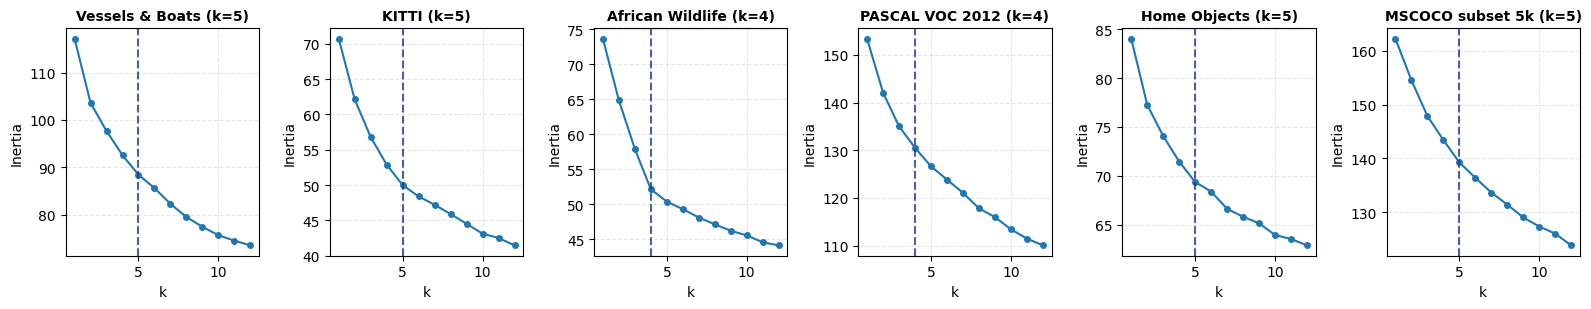

In [7]:
fig_k, axes_k = plt.subplots(1, len(resultados_globales), figsize=(16, 3.2), squeeze=False)
for ax, (nombre, datos) in zip(axes_k.flat, resultados_globales.items()):
    elbow = datos["elbow"]
    ax.plot(elbow["ks"], elbow["inertias"], "o-", linewidth=1.5, markersize=4)
    ax.axvline(elbow["k"], color="#1E3A8A", linestyle="--", alpha=0.8)
    ax.set_title(f"{nombre} (k={elbow['k']})", weight="bold", fontsize=10)
    ax.set_xlabel("k")
    ax.set_ylabel("Inertia")
    ax.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "elbow_method.pdf", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## 7. Domain View — real and synthetic points only

Joint t-SNE projections, **without classification, numerical metrics, decision boundaries or colored regions**. Blue circles = real; orange circles = synthetic. The image is a qualitative visualization, not a quantitative distance measurement.

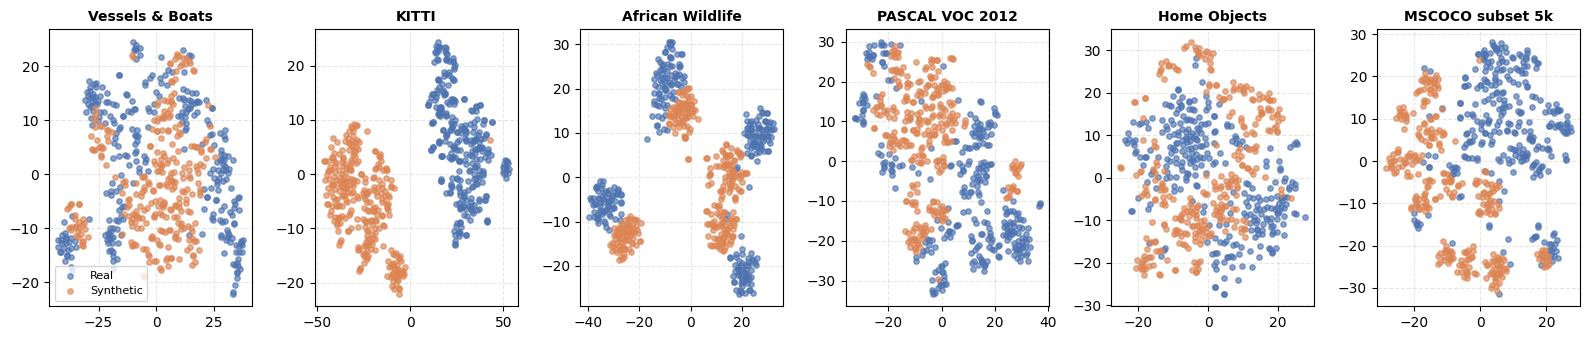

In [8]:
fig1, axes1 = plt.subplots(1, len(resultados_globales), figsize=(16, 3.5), squeeze=False)
for idx, (nombre, datos) in enumerate(resultados_globales.items()):
    ax = axes1.flat[idx]
    coor = datos["coordenadas"]
    n = datos["n_reales"]
    ax.scatter(coor[:n, 0], coor[:n, 1], c="#4C72B0", label="Real", alpha=0.65, s=15)
    ax.scatter(coor[n:, 0], coor[n:, 1], c="#DD8452", label="Synthetic", alpha=0.65, s=15)
    ax.set_title(nombre, weight="bold", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.3)
    if idx == 0:
        ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tsne_real_vs_synthetic.pdf", dpi=500,
            bbox_inches="tight", facecolor="white")
plt.show()

## 8. Cluster View — real-data semantic partitions

Colors denote **real-trained k-means clusters**, not dataset classes. Real samples use **circles** and synthetic samples use **squares**, both assigned in the **original normalized CLIP space**. t-SNE is used exclusively for display. Colors are consistent within each dataset for its selected `k`.

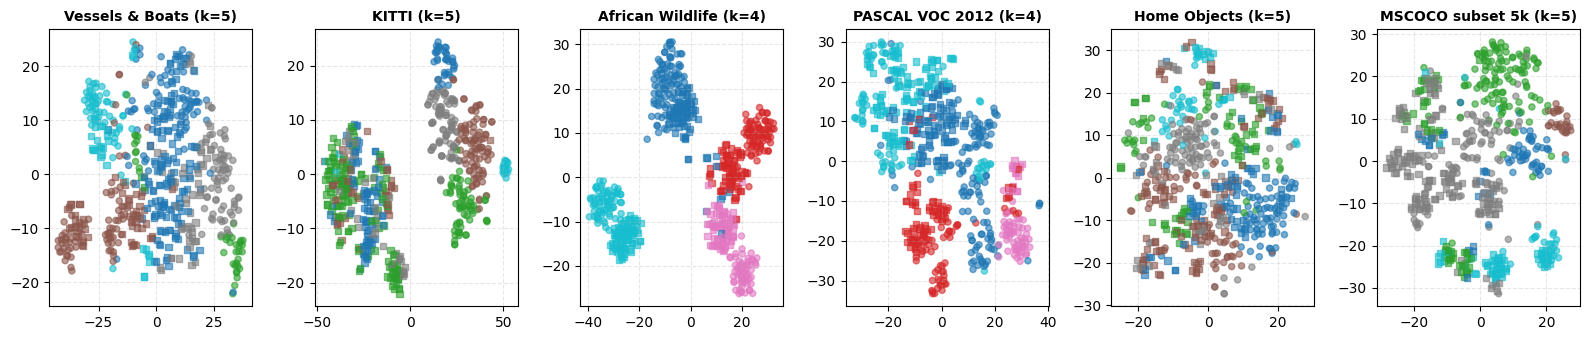

In [9]:
fig2, axes2 = plt.subplots(1, len(resultados_globales), figsize=(16, 3.5), squeeze=False)
for idx, (nombre, datos) in enumerate(resultados_globales.items()):
    ax = axes2.flat[idx]
    coor = datos["coordenadas"]
    n_real = datos["n_reales"]
    k = datos["k"]
    cmap = "tab10" if k <= 10 else "tab20"

    ax.scatter(coor[:n_real, 0], coor[:n_real, 1],
               c=datos["c_reales"], cmap=cmap, vmin=0, vmax=k-1,
               marker="o", s=20, alpha=0.6)
    ax.scatter(coor[n_real:, 0], coor[n_real:, 1],
               c=datos["c_sinteticos"], cmap=cmap, vmin=0, vmax=k-1,
               marker="s", s=20, alpha=0.6)

    ax.set_title(f"{nombre} (k={k})", weight="bold", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "tsne_semantic_clusters.pdf", dpi=500,
            bbox_inches="tight", facecolor="white")
plt.show()

## 9. Quantitative comparison of the datasets

The following table compares the CLIP-space metrics for all processed datasets. **No direct downstream detector-performance numbers are included**: the purpose is to investigate possible patterns before modifying the paper. For easier interpretation:

- Larger **mixing, coverage, density, precision, recall, cluster occupancy overlap** generally indicate more local similarity/coverage. Density can exceed 1; high density does not automatically mean more useful augmentation.
- Smaller **nearest-neighbor ratios**, smaller **synthetic-outside-p95 fraction**, and smaller **normalized synthetic centroid distance** generally indicate more compatibility with real images. These are different questions, not interchangeable domain-gap scores.
- The two projection diagnostics concern only the faithfulness of t-SNE to CLIP neighborhoods; they **are not domain-gap metrics**.

The CSV allows sorting or further statistical testing without recomputing CLIP embeddings.

In [10]:
filas = []
for nombre, d in resultados_globales.items():
    m, c, t = d["metricas"], d["clusters"], d["tsne"]
    filas.append({
        "dataset": nombre,
        "n_each": d["n_reales"],
        "k_clusters": d["k"],
        "mixing": m["mixing"],
        "mixing_R": m["mixing_R"],
        "mixing_S": m["mixing_S"],
        "density": m["density"],
        "coverage": m["coverage"],
        "precision": m["precision"],
        "recall": m["recall"],
        "nn_ratio_R_to_S": m["nn_ratio_R_to_S"],
        "nn_ratio_S_to_R": m["nn_ratio_S_to_R"],
        "cluster_occupancy_overlap": c["cluster_occupancy_overlap"],
        "centroid_outside_real_p95": c["centroid_outside_real_p95"],
        "centroid_radius_ratio_median": c["centroid_radius_ratio_median"],
        "tsne_neighbor_retention": t["tsne_neighbor_retention"],
        "tsne_trustworthiness": t["tsne_trustworthiness"],
    })

df = pd.DataFrame(filas).set_index("dataset")
display(df.round(3))
df.to_csv(FIGURES_DIR / "domain_gap_metrics.csv", float_format="%.6f")
print("Saved:", FIGURES_DIR / "domain_gap_metrics.csv")

,n_each,k_clusters,mixing,mixing_R,mixing_S,density,coverage,precision,recall,nn_ratio_R_to_S,nn_ratio_S_to_R,cluster_occupancy_overlap,centroid_outside_real_p95,centroid_radius_ratio_median,tsne_neighbor_retention,tsne_trustworthiness
dataset,,,,,,,,,,,,,,,,
Vessels & Boats,300,5,0.169,0.252,0.086,0.491,0.513,0.637,0.263,1.133,1.374,0.753,0.103,0.876,0.534,0.957
KITTI,300,5,0.003,0.000,0.007,0.000,0.000,0.000,0.160,2.379,1.631,0.623,1.000,1.598,0.544,0.963
African Wildlife,300,4,0.075,0.137,0.012,0.329,0.260,0.580,0.013,1.211,1.475,0.970,0.193,0.852,0.506,0.968
PASCAL VOC 2012,300,4,0.108,0.175,0.042,0.372,0.323,0.777,0.127,1.206,1.418,0.800,0.217,0.948,0.569,0.961
Home Objects,300,5,0.166,0.235,0.097,0.408,0.513,0.627,0.290,1.099,1.244,0.740,0.207,0.883,0.421,0.893
MSCOCO subset 5k,300,5,0.109,0.199,0.019,0.487,0.310,0.787,0.047,1.174,1.492,0.607,0.120,0.917,0.581,0.957


Saved: figures/domain_gap_metrics.csv


### 9.1 Bounded measures — direct comparison

These values are between 0 and 1, except they are **not all expected to reach 1** in an equal-distribution experiment (e.g., mixing is close to 0.5 and coverage is near \(1-2^{-k}\)). A higher value is only a descriptive indication of greater local mixing / coverage / cluster occupancy, not a guarantee of better detector AP.

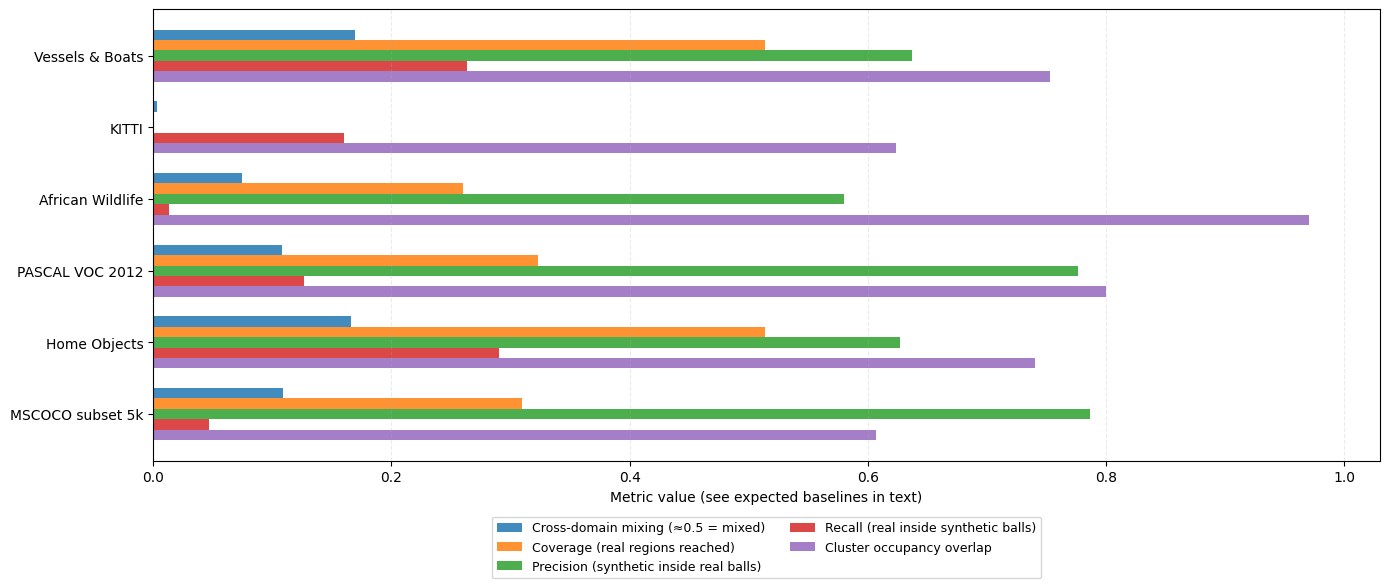

In [11]:
metricas_01 = [
    ("mixing", "Cross-domain mixing (≈0.5 = mixed)"),
    ("coverage", "Coverage (real regions reached)"),
    ("precision", "Precision (synthetic inside real balls)"),
    ("recall", "Recall (real inside synthetic balls)"),
    ("cluster_occupancy_overlap", "Cluster occupancy overlap"),
]
fig, ax = plt.subplots(figsize=(14, 6))
labels = list(df.index)
y = np.arange(len(labels))
height = 0.145
for j, (campo, etiqueta) in enumerate(metricas_01):
    desplazamiento = (j - (len(metricas_01)-1)/2) * height
    ax.barh(y + desplazamiento, df[campo], height=height, label=etiqueta, alpha=0.85)
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set_xlim(0, 1.03)
ax.set_xlabel("Metric value (see expected baselines in text)")
ax.grid(True, axis="x", linestyle="--", alpha=.25)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "domain_gap_bounded_metrics.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

### 9.2 Density, directional distance ratios and cluster distance

These measures have **different scales** and must not be overlaid on a shared numerical axis. Density is unbounded. The nearest-neighbor distance ratios compare cross-domain nearest images with own-domain nearest images; a ratio of 1 indicates similar typical nearest-neighbor distances. `centroid_outside_real_p95` is the fraction of synthetics outside the assigned cluster's real p95 centroid radius (a coarse diagnostic, not a manifold test).

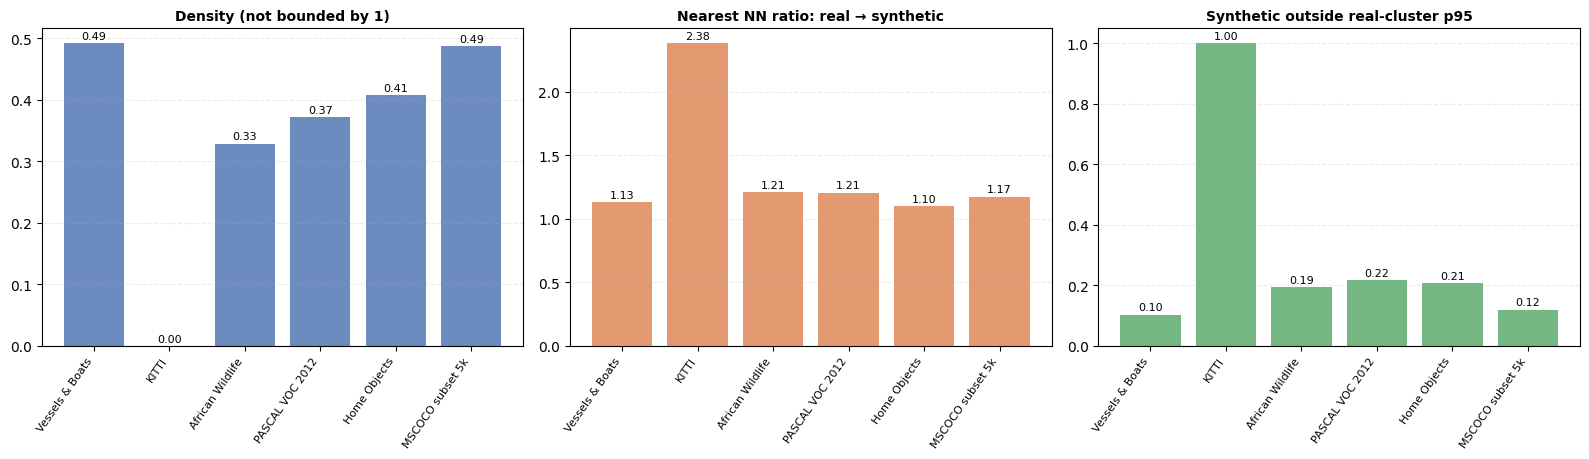

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.7), squeeze=False)
axes = axes.flat
campos = [
    ("density", "Density (not bounded by 1)", "#4C72B0"),
    ("nn_ratio_R_to_S", "Nearest NN ratio: real → synthetic", "#DD8452"),
    ("centroid_outside_real_p95", "Synthetic outside real-cluster p95", "#55A868"),
]
for ax, (campo, titulo, color) in zip(axes, campos):
    valores = df[campo]
    ax.bar(np.arange(len(df)), valores, color=color, alpha=0.82)
    ax.set_title(titulo, fontsize=10, weight="bold")
    ax.set_xticks(np.arange(len(df)), [str(x) for x in df.index], rotation=55, ha="right", fontsize=8)
    ax.grid(True, axis="y", linestyle="--", alpha=0.25)
    for j, valor in enumerate(valores):
        ax.annotate(f"{valor:.2f}", (j, valor), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "domain_gap_additional_metrics.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

# Full directional detail remains in domain_gap_metrics.csv, including synthetic → real NN ratio.

## 10. Cluster diagnostics: same CLIP cluster, separated in t-SNE

A k-means cluster is a Voronoi region in **512-D CLIP space**. Its projection can look like separate islands in t-SNE because t-SNE can tear or bend global structure while approximately preserving local neighborhoods. Therefore, **same cluster color does not imply 2D connectedness**, and visually distant points can still share a CLIP centroid.

We quantify this using two diagnostics (computed from joint real + synthetic embeddings):

- **Neighbor retention @k:** percentage of each point's k nearest CLIP neighbors that also remain among its k nearest neighbors in t-SNE (1 = exact agreement).
- **Trustworthiness @k:** standard t-SNE manifold trustworthiness (1 = excellent neighborhood fidelity). It penalizes spurious neighbors in 2D but does **not** guarantee cluster connectivity or identical global geometry.

These diagnostics are intentionally **separate** from the domain-gap analysis, and do not use t-SNE to make any distribution-proximity claim.

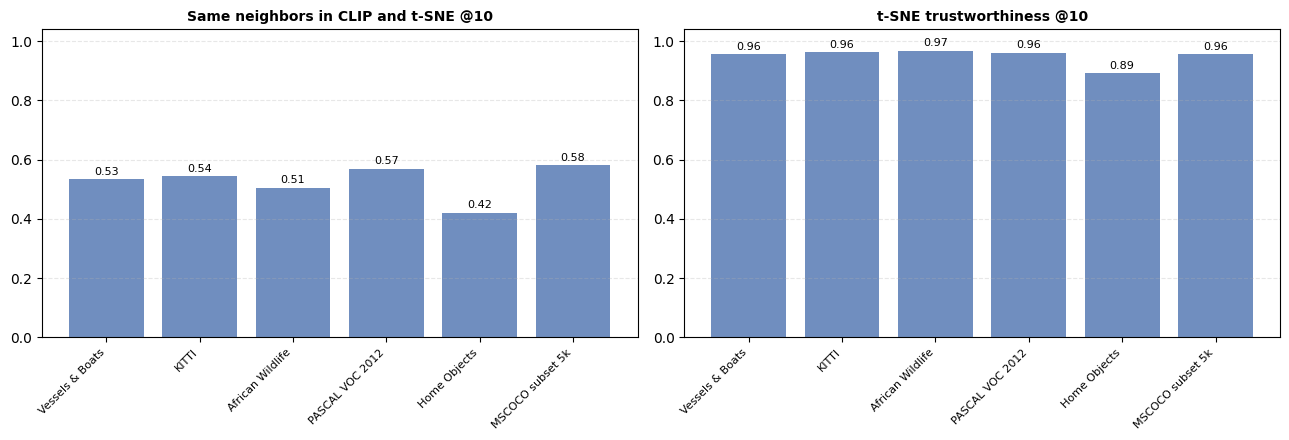

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), squeeze=False)
for ax, (campo, titulo) in zip(axes.flat, [
    ("tsne_neighbor_retention", f"Same neighbors in CLIP and t-SNE @{K_DIAGNOSTICO}"),
    ("tsne_trustworthiness", f"t-SNE trustworthiness @{K_DIAGNOSTICO}"),
]):
    ax.bar(np.arange(len(df)), df[campo], color="#4C72B0", alpha=0.8)
    ax.set_xticks(np.arange(len(df)), [str(x) for x in df.index], rotation=45, ha="right", fontsize=8)
    ax.set_title(titulo, weight="bold", fontsize=10)
    ax.set_ylim(0, 1.04)
    ax.grid(True, axis="y", linestyle="--", alpha=.3)
    for j, val in enumerate(df[campo]):
        ax.text(j, val+.015, f"{val:.2f}", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tsne_neighborhood_diagnostics.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

## 11. Optional sensitivity to neighborhood size

Coverage, Density and Precision/Recall are sensitive to the number of neighbors defining each ball. Compare `k=3,5,10` on the **same CLIP samples** (no resampling), to see whether a dataset's apparent domain gap is stable or depends on this choice. `Mixing` uses the same k in this sensitivity display; the default main analysis uses `K_MEZCLA=10`.

,dataset,k,mixing,coverage,density,precision,recall
0,Vessels & Boats,3,0.114,0.370,0.488,0.533,0.127
1,Vessels & Boats,5,0.138,0.513,0.491,0.637,0.263
2,Vessels & Boats,10,0.169,0.713,0.548,0.827,0.477
3,KITTI,3,0.002,0.000,0.000,0.000,0.093
4,KITTI,5,0.003,0.000,0.000,0.000,0.160
5,KITTI,10,0.003,0.000,0.000,0.000,0.250
6,African Wildlife,3,0.054,0.180,0.299,0.477,0.010
7,African Wildlife,5,0.058,0.260,0.329,0.580,0.013
8,African Wildlife,10,0.075,0.410,0.375,0.730,0.057
9,PASCAL VOC 2012,3,0.063,0.217,0.316,0.563,0.070


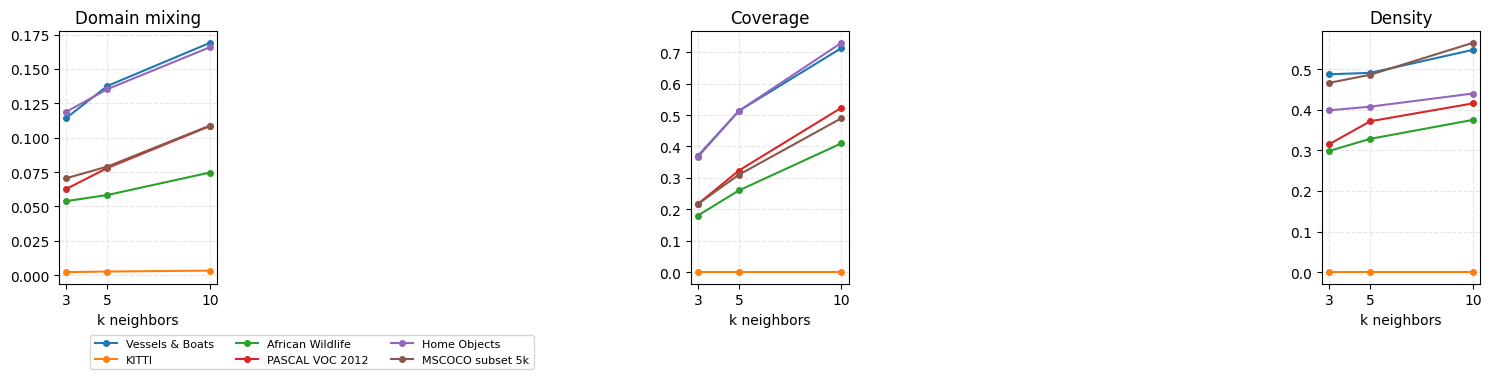

In [14]:
if ANALISIS_SENSIBILIDAD:
    filas_sens = []
    for nombre, d in resultados_globales.items():
        for k in K_SENSIBILIDAD:
            m = metricas_vecindad(d["embs_reales"], d["embs_sinteticos"],
                                  k_bolas=k, k_mezcla=k)
            filas_sens.append({"dataset": nombre, "k": k,
                               "mixing": m["mixing"], "coverage": m["coverage"],
                               "density": m["density"], "precision": m["precision"],
                               "recall": m["recall"]})
    df_sens = pd.DataFrame(filas_sens)
    display(df_sens.round(3))
    df_sens.to_csv(FIGURES_DIR / "domain_gap_k_sensitivity.csv", index=False)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4), squeeze=False)
    for ax, campo, titulo in zip(axes.flat, ["mixing", "coverage", "density"],
                                  ["Domain mixing", "Coverage", "Density"]):
        for nombre, tabla in df_sens.groupby("dataset", sort=False):
            ax.plot(tabla["k"], tabla[campo], "o-", markersize=4, label=nombre)
        ax.set_xticks(K_SENSIBILIDAD)
        ax.set_xlabel("k neighbors")
        ax.set_title(titulo)
        ax.grid(True, alpha=.3, linestyle="--")
    axes.flat[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(1.6,-.18), ncol=3)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "domain_gap_k_sensitivity.png", dpi=300,
                bbox_inches="tight", facecolor="white")
    plt.show()


## Reproducibility and interpretation notes

- **Model**: frozen `openai/clip-vit-base-patch32`; L2 normalization applied before all distances and clustering.
- **Sampling**: seeded (`RANDOM_STATE=42`) random selection of up to 300 **valid** images per domain; balanced `n` printed for each dataset.
- **k-means**: fitted only to real CLIP vectors; k determined separately by deterministic elbow selection. Synthetic vectors assigned with `predict()` in the same original space.
- **t-SNE**: fitted jointly for display; **Domain View is only blue/orange points**, and the Cluster View uses CLIP cluster labels. Neither uses linear classifiers, accuracy, boundaries, or interpolated classifier scores.
- **Density/Coverage**: reproduce the sample-based formulas of Naeem et al. (2020) with real-domain radii. Precision/recall use the k-NN ball-union representation (Kynkäänniemi et al., 2019). These are evaluated in CLIP features rather than the Inception feature space sometimes used in the generative-model literature.
- **Sensitivity**: fixed-sample k variation. With sample sizes this small and heterogeneous image categories, interpret ordering as **exploratory**. Cross-dataset comparisons can reflect content mix and generator differences as well as the gap of interest. If patterns appear, test other random seeds and larger samples.
- **No AP table, no logistic regression**: detector improvements are not embedded in these calculations or figures.

**Artifacts:** `figures/elbow_method.png`, `figures/tsne_real_vs_synthetic.png`, `figures/tsne_semantic_clusters.png`, `figures/domain_gap_metrics.csv`, `figures/domain_gap_bounded_metrics.png`, `figures/domain_gap_additional_metrics.png`, `figures/tsne_neighborhood_diagnostics.png`, plus optional sensitivity figures and CSV.

# Plotting metrics for paper

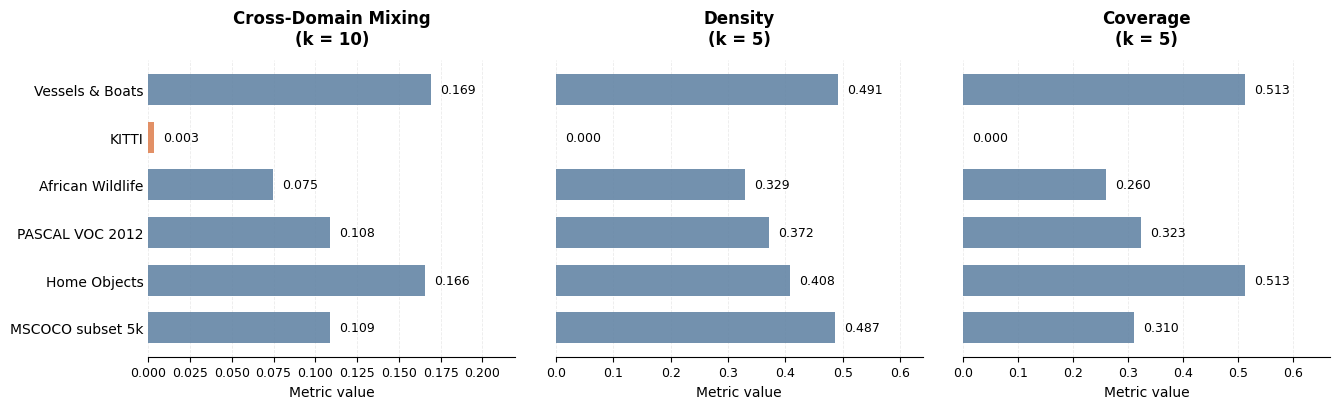

In [15]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Figure: Real-to-Synthetic Domain Gap Metrics
# ============================================================

metrics = [
    ("mixing", "Cross-Domain Mixing", "k = 10"),
    ("density", "Density", "k = 5"),
    ("coverage", "Coverage", "k = 5"),
]

datasets = list(df.index)
y = np.arange(len(datasets))

COLOR_OTHER = "#6485A5"
COLOR_KITTI = "#DF8455"

colors = [
    COLOR_KITTI if name == "KITTI" else COLOR_OTHER
    for name in datasets
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(13.5, 4.2),
    sharey=True
)

for ax, (column, title, k_label) in zip(axes, metrics):

    values = df[column].to_numpy(dtype=float)

    ax.barh(
        y,
        values,
        height=0.65,
        color=colors,
        edgecolor="none",
        alpha=0.9,
        zorder=3
    )

    ax.set_title(
        f"{title}\n({k_label})",
        fontsize=12,
        fontweight="bold",
        pad=12
    )

    # Independent scales: Density is not bounded by 1.
    upper = max(float(np.max(values)) * 1.30, 0.05)
    ax.set_xlim(0, upper)

    for i, value in enumerate(values):
        ax.text(
            value + upper * 0.025,
            i,
            f"{value:.3f}",
            va="center",
            ha="left",
            fontsize=9
        )

    ax.grid(
        axis="x",
        linestyle="--",
        linewidth=0.6,
        alpha=0.25,
        zorder=0
    )

    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", labelsize=9)

    ax.set_xlabel(
        "Metric value",
        fontsize=10
    )

# Dataset labels only in the first panel
axes[0].set_yticks(y)
axes[0].set_yticklabels(datasets, fontsize=10)
axes[0].invert_yaxis()

for ax in axes[1:]:
    ax.tick_params(axis="y", labelleft=False)

plt.tight_layout(w_pad=2.2)

# Save raster and vector versions
plt.savefig(
    FIGURES_DIR / "domain_gap_three_metrics.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    FIGURES_DIR / "domain_gap_three_metrics.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
